# Beauty & Fashion Stocks: Return and Risk Analyser
**Author:** Apara Bhargava · **Tools:** Python (pandas, NumPy, matplotlib, yfinance) in Google Colab

**Question:** How do Indian and global beauty & fashion stocks compare on return and risk, and does combining them build a better portfolio?

**Stocks (9):**
- **Global:** e.l.f. Beauty, Estée Lauder, Coty, Tapestry (US) · L'Oréal, LVMH (France)
- **India:** Honasa Consumer (Mamaearth), Nykaa (FSN E-Commerce), Trent (Zudio, Westside)
- **Benchmarks (for comparison only):** S&P 500, Nifty 50

**Period:** 8 Nov 2023 (the first full trading day after Honasa listed) to today.
**Currency:** all prices converted to **US dollars**, the view of a US-based investor, so returns can be compared fairly.

*How to run: Runtime → Run all. Each step below explains the finance idea first, then the code line by line.*

## Step 1: Install and import the tools
A **library** is ready-made code. We use:
- `yfinance`: downloads share prices from Yahoo Finance
- `pandas`: tables of data (like Excel in Python)
- `numpy`: maths
- `matplotlib`: charts

In [1]:
!pip install yfinance -q          # install yfinance (Colab already has the others)

import yfinance as yf              # 'as yf' gives the library a short nickname
import pandas as pd                # pandas = data tables
import numpy as np                 # numpy = maths (square roots, random numbers)
import matplotlib.pyplot as plt    # matplotlib = charts

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')  # show numbers with 4 decimals
print('Libraries loaded')

Libraries loaded


## Step 2: Settings
We store every choice in one place so it is easy to change.
- **Risk-free rate:** the return you get with no risk. We use the US 10-year Treasury yield, **4.98%** (Federal Reserve H.15, 29 Oct 2026), the same rate as the e.l.f. DCF in Project 1.
- **252** = number of trading days in a year (markets close on weekends and holidays).

In [2]:
START_DATE = '2023-11-08'      # first full trading day after Honasa listed (7 Nov 2023)
RISK_FREE = 0.0498             # US 10-year Treasury yield, Fed H.15, 29 Oct 2026
TRADING_DAYS = 252             # trading days in one year

# A dictionary: ticker -> (company name, group, currency)
STOCKS = {
    'ELF':       ('e.l.f. Beauty',   'Global', 'USD'),
    'EL':        ('Estée Lauder',    'Global', 'USD'),
    'COTY':      ('Coty',            'Global', 'USD'),
    'TPR':       ('Tapestry',        'Global', 'USD'),
    'OR.PA':     ("L'Oréal",         'Global', 'EUR'),
    'MC.PA':     ('LVMH',            'Global', 'EUR'),
    'HONASA.NS': ('Honasa (Mamaearth)', 'India', 'INR'),
    'NYKAA.NS':  ('Nykaa',           'India', 'INR'),
    'TRENT.NS':  ('Trent',           'India', 'INR'),
}
BENCHMARKS = {
    '^GSPC': ('S&P 500',  'Benchmark', 'USD'),
    '^NSEI': ('Nifty 50', 'Benchmark', 'INR'),
}
FX = {'INR=X': 'Rupees per 1 US dollar', 'EURUSD=X': 'US dollars per 1 euro'}

ALL = {**STOCKS, **BENCHMARKS}                     # join the two dictionaries
NAMES = {t: v[0] for t, v in ALL.items()}          # ticker -> name, used to label charts
print(len(STOCKS), 'stocks,', len(BENCHMARKS), 'benchmarks')

9 stocks, 2 benchmarks


## Step 3: Download prices
`auto_adjust=True` gives prices **adjusted for dividends and stock splits**, so returns are the true total return.
We also download two exchange rates so we can convert rupees and euros into dollars.

In [3]:
tickers = list(ALL) + list(FX)                      # every symbol we need
raw = yf.download(tickers, start=START_DATE, auto_adjust=True, progress=False)
prices = raw['Close']                               # keep only the closing price

# Check: did every ticker download?
missing = [t for t in tickers if t not in prices.columns or prices[t].dropna().empty]
print('Missing tickers:', missing if missing else 'none')
prices.tail()                                       # show the last 5 rows

Missing tickers: none


Ticker,COTY,EL,ELF,EURUSD=X,HONASA.NS,INR=X,MC.PA,NYKAA.NS,OR.PA,TPR,TRENT.NS,^GSPC,^NSEI
Date,,,,,,,,,,,,,
2026-10-30,3.4000,109.2300,111.6900,1.1183,442.1000,95.1524,387.0000,349.3500,436.9500,116.2900,"3,017.3000","7,580.0698","23,053.0996"
2026-11-02,3.4800,104.7700,110.6800,1.1157,452.7500,94.9050,393.6500,353.6500,436.5000,120.7600,"3,046.3999","7,541.3999","23,440.8008"
2026-11-03,3.2900,105.3900,111.5000,1.1192,457.2000,94.7254,401.5000,353.9000,432.7000,121.0200,"3,036.5000","7,568.9199","23,810.8496"
2026-11-04,3.4700,112.0400,113.6300,1.1207,461.7500,94.7484,416.2500,355.5000,444.7500,125.3100,"3,060.0000","7,688.6201","23,960.5996"
2026-11-05,4.0350,108.4400,111.4100,1.1237,481.7500,94.4650,418.6500,350.3000,455.6000,133.2800,"3,055.0000","7,410.8301","24,536.5996"


## Step 4: Clean the data and convert to US dollars
- Indian, French and US markets have **different holidays**, so some days have gaps. `ffill()` fills a gap with the previous day's price (the price did not change because the market was closed).
- **Rupee to dollar:** price in ₹ ÷ (₹ per $1). **Euro to dollar:** price in € × ($ per €1).

In [4]:
prices = prices.ffill()                                   # fill holiday gaps with the last price
fx_inr = prices['INR=X']                                  # rupees per dollar
fx_eur = prices['EURUSD=X']                               # dollars per euro

usd = pd.DataFrame(index=prices.index)                    # empty table with the same dates
for t, (name, group, ccy) in ALL.items():                 # loop over every stock and benchmark
    if t in missing:                                      # skip any ticker that failed to download
        continue
    if ccy == 'USD':
        usd[t] = prices[t]                                # already in dollars
    elif ccy == 'INR':
        usd[t] = prices[t] / fx_inr                       # rupees -> dollars
    elif ccy == 'EUR':
        usd[t] = prices[t] * fx_eur                       # euros -> dollars

usd = usd.dropna()                                        # keep only dates where every price exists
print('From', usd.index[0].date(), 'to', usd.index[-1].date(), '|', len(usd), 'trading days')
usd.tail()

From 2023-11-08 to 2026-11-05 | 781 trading days


,ELF,EL,COTY,TPR,OR.PA,MC.PA,HONASA.NS,NYKAA.NS,TRENT.NS,^GSPC,^NSEI
Date,,,,,,,,,,,
2026-10-30,111.6900,109.2300,3.4000,116.2900,488.6327,432.7746,4.6462,3.6715,31.7102,"7,580.0698",242.2756
2026-11-02,110.6800,104.7700,3.4800,120.7600,486.9967,439.1896,4.7706,3.7264,32.0995,"7,541.3999",246.9923
2026-11-03,111.5000,105.3900,3.2900,121.0200,484.2807,449.3615,4.8266,3.7361,32.0558,"7,568.9199",251.3671
2026-11-04,113.6300,112.0400,3.4700,125.3100,498.4422,466.5015,4.8734,3.7520,32.2961,"7,688.6201",252.8866
2026-11-05,111.4100,108.4400,4.0350,133.2800,511.9676,470.4461,5.0998,3.7083,32.3400,"7,410.8301",259.7428


## Step 5: Growth of $100
If you had invested **$100** in each stock on the start date, what would it be worth today?
We divide each price by its first price and multiply by 100.

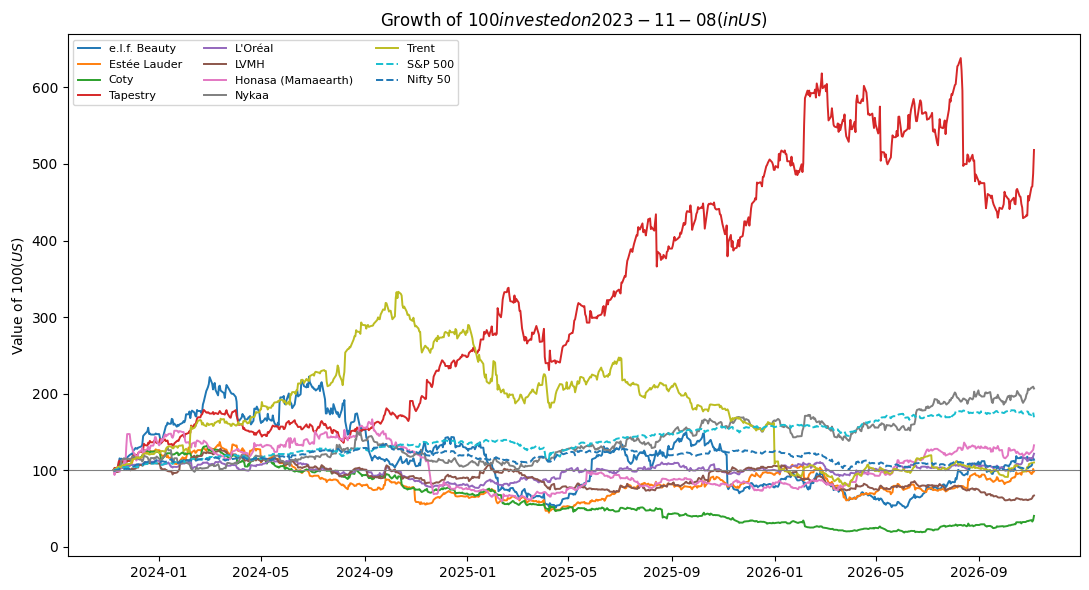

In [5]:
growth = usd / usd.iloc[0] * 100                     # iloc[0] = the first row (start date)

fig, ax = plt.subplots(figsize=(11, 6))               # create an empty chart
for t in growth.columns:
    style = '--' if ALL[t][1] == 'Benchmark' else '-' # dashed lines for benchmarks
    ax.plot(growth.index, growth[t], style, label=NAMES[t], linewidth=1.4)
ax.axhline(100, color='grey', linewidth=0.8)          # the $100 starting line
ax.set_title('Growth of $100 invested on ' + str(usd.index[0].date()) + ' (in US$)')
ax.set_ylabel('Value of $100 (US$)')
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig('growth_of_100.png', dpi=150)              # save the chart for GitHub
plt.show()

## Step 6: Daily returns
A **daily return** is the % change in price from one day to the next:

return = today's price ÷ yesterday's price − 1

Everything else (risk, Sharpe, correlation, portfolios) is built from daily returns.

In [6]:
returns = usd.pct_change().dropna()     # pct_change() = % change from the previous row
returns.head()

,ELF,EL,COTY,TPR,OR.PA,MC.PA,HONASA.NS,NYKAA.NS,TRENT.NS,^GSPC,^NSEI
Date,,,,,,,,,,,
2023-11-09,0.0133,-0.0110,-0.0259,0.0299,0.0099,0.0169,-0.0631,-0.0122,0.0105,-0.0081,-0.0023
2023-11-10,-0.0438,-0.0049,0.0020,-0.0057,-0.0153,-0.0421,0.0510,0.0150,0.0033,0.0156,0.0003
2023-11-13,0.0230,-0.0089,0.0082,0.0139,0.0031,0.0042,0.0004,0.0113,0.0283,-0.0008,0.0012
2023-11-14,0.0918,0.0799,0.0952,0.0702,0.0251,0.0278,0.0012,0.0012,0.0012,0.0191,0.0012
2023-11-15,0.0659,0.0265,0.0019,0.0121,0.0148,0.0339,-0.0081,0.0195,0.0003,0.0016,0.0146


## Step 7: Return and risk for each stock
| Measure | What it means | Formula |
|---|---|---|
| **Annual return (CAGR)** | Average yearly growth | (end price ÷ start price)^(1 ÷ years) − 1 |
| **Volatility** | How much the price swings: our measure of **risk** | standard deviation of daily returns × √252 |
| **Sharpe ratio** | Extra return per unit of risk (higher = better) | (annual return − risk-free rate) ÷ volatility |
| **Maximum drawdown** | Worst fall from a peak to a low | lowest value of (price ÷ highest price so far − 1) |

In [7]:
def max_drawdown(price_series):
    peak = price_series.cummax()                    # highest price reached so far, each day
    drawdown = price_series / peak - 1              # how far below that peak we are
    return drawdown.min()                           # the worst (most negative) value

years = len(returns) / TRADING_DAYS                 # length of the period in years

rows = []                                           # we collect one row per stock
for t in usd.columns:
    cagr = (usd[t].iloc[-1] / usd[t].iloc[0]) ** (1 / years) - 1
    vol = returns[t].std() * np.sqrt(TRADING_DAYS)
    sharpe = (cagr - RISK_FREE) / vol
    rows.append({'Ticker': t, 'Company': NAMES[t], 'Group': ALL[t][1],
                 'Annual return': cagr, 'Volatility': vol,
                 'Sharpe ratio': sharpe, 'Max drawdown': max_drawdown(usd[t])})

summary = pd.DataFrame(rows).set_index('Ticker').sort_values('Sharpe ratio', ascending=False)
summary.to_csv('stock_summary.csv')                 # save the table
summary

,Company,Group,Annual return,Volatility,Sharpe ratio,Max drawdown
Ticker,,,,,,
TPR,Tapestry,Global,0.7017,0.3898,1.6724,-0.3277
^GSPC,S&P 500,Benchmark,0.1849,0.1480,0.9131,-0.1890
NYKAA.NS,Nykaa,India,0.2643,0.3091,0.6940,-0.3269
HONASA.NS,Honasa (Mamaearth),India,0.0950,0.4433,0.1020,-0.6441
OR.PA,L'Oréal,Global,0.0648,0.2508,0.0597,-0.3241
ELF,e.l.f. Beauty,Global,0.0418,0.6331,-0.0126,-0.7726
TRENT.NS,Trent,India,0.0313,0.4171,-0.0443,-0.7636
^NSEI,Nifty 50,Benchmark,0.0349,0.1477,-0.1012,-0.2671
EL,Estée Lauder,Global,-0.0056,0.4622,-0.1199,-0.6759


## Step 8: Risk vs return map
Each dot is one stock. **Top-left is best** (high return, low risk); bottom-right is worst.

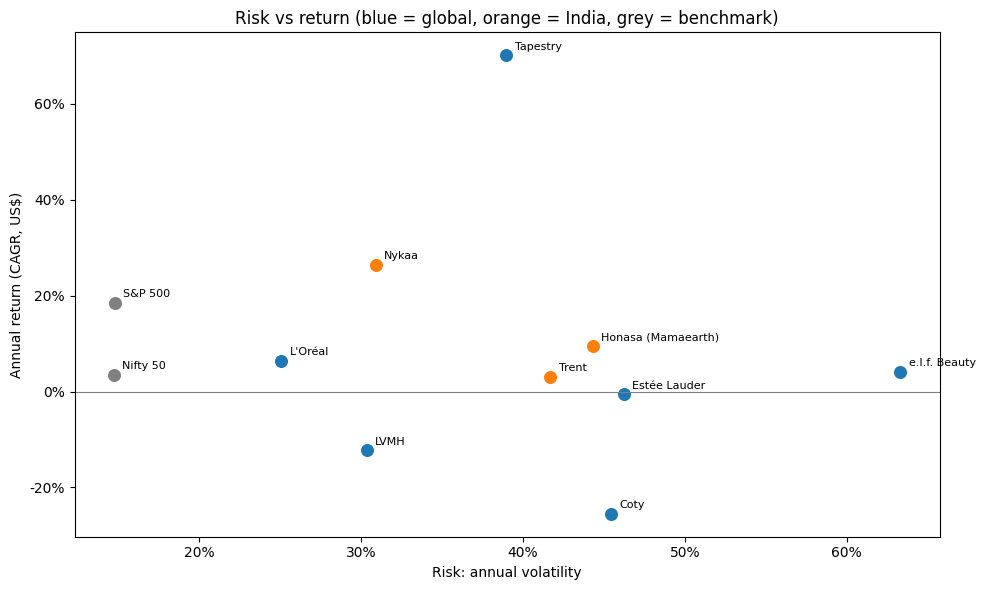

In [8]:
colors = {'Global': 'tab:blue', 'India': 'tab:orange', 'Benchmark': 'grey'}
fig, ax = plt.subplots(figsize=(10, 6))
for t, r in summary.iterrows():                      # iterrows() loops over table rows
    ax.scatter(r['Volatility'], r['Annual return'], color=colors[r['Group']], s=70)
    ax.annotate(r['Company'], (r['Volatility'], r['Annual return']),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xlabel('Risk: annual volatility')
ax.set_ylabel('Annual return (CAGR, US$)')
ax.set_title('Risk vs return (blue = global, orange = India, grey = benchmark)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))   # show as %
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.tight_layout(); plt.savefig('risk_return_map.png', dpi=150); plt.show()

## Step 9: Drawdowns over time
How deep did each stock fall from its high, and how long did it stay down?

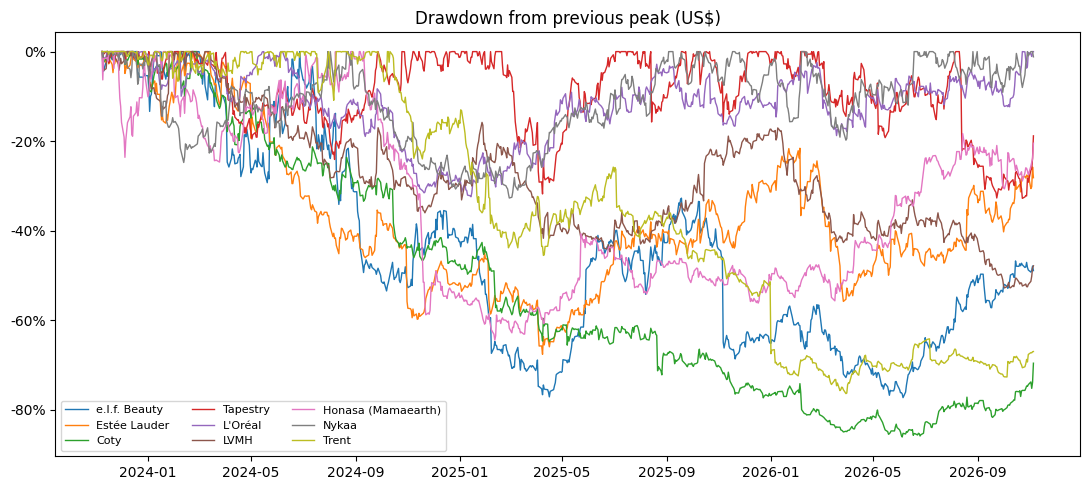

In [9]:
stock_cols = [t for t in usd.columns if ALL[t][1] != 'Benchmark']
dd = usd[stock_cols] / usd[stock_cols].cummax() - 1      # drawdown for every stock, every day

fig, ax = plt.subplots(figsize=(11, 5))
for t in stock_cols:
    ax.plot(dd.index, dd[t], label=NAMES[t], linewidth=1)
ax.set_title('Drawdown from previous peak (US$)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig('drawdowns.png', dpi=150); plt.show()

## Step 10: Correlation heatmap
**Correlation** measures whether two stocks move together:
- **+1** = always move in the same direction
- **0** = no relationship
- **−1** = move in opposite directions

Low correlation is useful: when one stock falls, the other may not, so a mix is **less risky** (this is **diversification**).

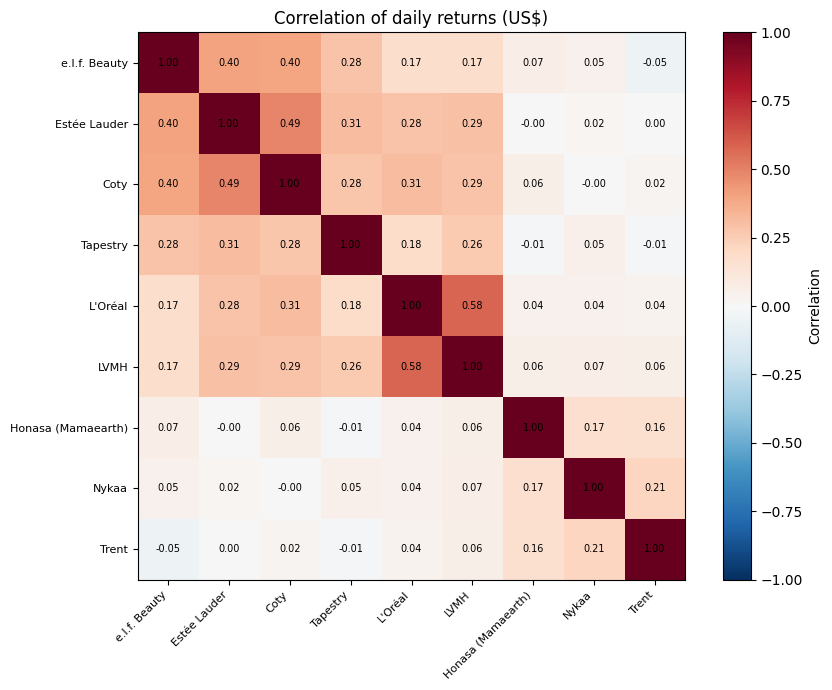

Average correlation within India : 0.18
Average correlation within Global: 0.31
Average correlation India-Global : 0.03


In [10]:
corr = returns[stock_cols].corr()                      # correlation table
labels = [NAMES[t] for t in corr.columns]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)    # red = move together, blue = opposite
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):                           # write each number in its square
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Correlation of daily returns (US$)')
plt.tight_layout(); plt.savefig('correlation_heatmap.png', dpi=150); plt.show()

india = [t for t in stock_cols if ALL[t][1] == 'India']
glob = [t for t in stock_cols if ALL[t][1] == 'Global']
print('Average correlation within India :', round(corr.loc[india, india].values[np.triu_indices(len(india), 1)].mean(), 2))
print('Average correlation within Global:', round(corr.loc[glob, glob].values[np.triu_indices(len(glob), 1)].mean(), 2))
print('Average correlation India-Global :', round(corr.loc[india, glob].values.mean(), 2))

## Step 11: Portfolios
A **portfolio** is a mix of stocks. Its return is the weighted average of the stocks' returns, but its risk is usually **lower** than the average risk, because stocks do not all fall at the same time.

We compare:
1. **Equal-weight India**: 1/3 in each Indian stock
2. **Equal-weight Global**: 1/6 in each global stock
3. **Equal-weight All**: 1/9 in each stock
4. **Optimised (maximum Sharpe)**: we try **10,000 random mixes** and keep the one with the best return per unit of risk
5. **Minimum risk**: the random mix with the lowest volatility

*Formula for portfolio volatility:* √(weights × covariance table × weights) × √252. The **covariance** combines each stock's risk with how it moves with the others.

In [11]:
def portfolio_stats(weights, tickers):
    w = np.array(weights)
    r = returns[tickers]
    daily = r.dot(w)                                       # portfolio daily return = weighted sum
    growth_path = (1 + daily).cumprod()                    # value of $1 over time
    cagr = growth_path.iloc[-1] ** (1 / years) - 1
    vol = np.sqrt(w @ r.cov().values @ w) * np.sqrt(TRADING_DAYS)
    return cagr, vol, (cagr - RISK_FREE) / vol, max_drawdown(growth_path)

# --- 10,000 random portfolios across all 9 stocks ---
np.random.seed(42)                                         # same random numbers every run
n = len(stock_cols)
results = []
for _ in range(10000):
    w = np.random.random(n)                                # random numbers
    w = w / w.sum()                                        # make them add up to 100%
    cagr, vol, sharpe, mdd = portfolio_stats(w, stock_cols)
    results.append((cagr, vol, sharpe, w))

sims = pd.DataFrame(results, columns=['Return', 'Volatility', 'Sharpe', 'Weights'])
best = sims.loc[sims['Sharpe'].idxmax()]                   # highest Sharpe ratio
safest = sims.loc[sims['Volatility'].idxmin()]             # lowest risk

# --- compare the portfolios ---
ports = {
    'Equal-weight India':  ([1/len(india)] * len(india), india),
    'Equal-weight Global': ([1/len(glob)] * len(glob), glob),
    'Equal-weight All':    ([1/n] * n, stock_cols),
    'Optimised (max Sharpe)': (best['Weights'], stock_cols),
    'Minimum risk':        (safest['Weights'], stock_cols),
}
port_rows = []
for name, (w, tk) in ports.items():
    cagr, vol, sharpe, mdd = portfolio_stats(w, tk)
    port_rows.append({'Portfolio': name, 'Annual return': cagr, 'Volatility': vol,
                      'Sharpe ratio': sharpe, 'Max drawdown': mdd})
port_table = pd.DataFrame(port_rows).set_index('Portfolio')
port_table.to_csv('portfolio_summary.csv')
port_table

,Annual return,Volatility,Sharpe ratio,Max drawdown
Portfolio,,,,
Equal-weight India,0.1765,0.2639,0.4801,-0.4603
Equal-weight Global,0.0959,0.2765,0.1666,-0.4541
Equal-weight All,0.1396,0.2084,0.4308,-0.3328
Optimised (max Sharpe),0.3288,0.2149,1.2979,-0.1868
Minimum risk,0.1814,0.1752,0.7510,-0.2512


### Weights of the optimised portfolios

In [12]:
weights = pd.DataFrame({'Max Sharpe': best['Weights'], 'Minimum risk': safest['Weights']},
                       index=[NAMES[t] for t in stock_cols])
weights.to_csv('optimised_weights.csv')
weights.style.format('{:.1%}')

,Max Sharpe,Minimum risk
e.l.f. Beauty,4.6%,0.8%
Estée Lauder,10.9%,6.0%
Coty,4.1%,3.3%
Tapestry,34.8%,10.2%
L'Oréal,10.9%,22.7%
LVMH,4.6%,9.5%
Honasa (Mamaearth),7.0%,15.3%
Nykaa,20.8%,22.8%
Trent,2.3%,9.2%


## Step 12: The efficient frontier
Each grey dot is one random portfolio. The upper-left edge of the cloud is the **efficient frontier**: the best return available for each level of risk.

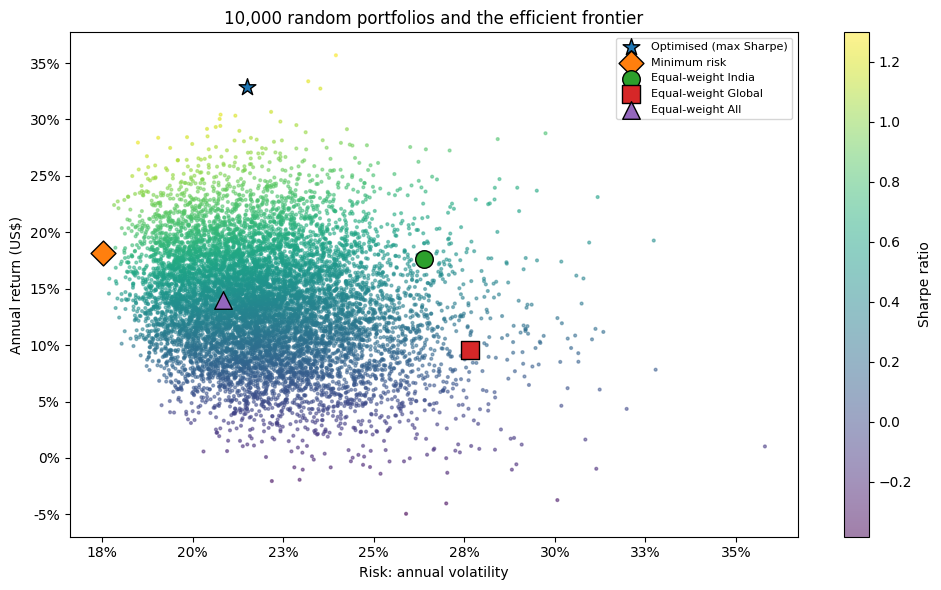

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(sims['Volatility'], sims['Return'], c=sims['Sharpe'], cmap='viridis', s=4, alpha=0.5)
plt.colorbar(sc, ax=ax, label='Sharpe ratio')
for name, marker in [('Optimised (max Sharpe)', '*'), ('Minimum risk', 'D'),
                     ('Equal-weight India', 'o'), ('Equal-weight Global', 's'), ('Equal-weight All', '^')]:
    r = port_table.loc[name]
    ax.scatter(r['Volatility'], r['Annual return'], marker=marker, s=160, edgecolor='black', label=name)
ax.set_xlabel('Risk: annual volatility'); ax.set_ylabel('Annual return (US$)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('10,000 random portfolios and the efficient frontier')
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('efficient_frontier.png', dpi=150); plt.show()

## Step 13: Save the results
This downloads the tables and charts to your computer. Upload them to GitHub with the notebook, and send the two CSV files to Claude to write up the findings.

In [14]:
from google.colab import files     # Colab's tool for downloading files
for f in ['stock_summary.csv', 'portfolio_summary.csv', 'optimised_weights.csv',
          'growth_of_100.png', 'risk_return_map.png', 'drawdowns.png',
          'correlation_heatmap.png', 'efficient_frontier.png']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 14: Findings
Period: 8 Nov 2023 to 5 Nov 2026, in US dollars (5 Nov prices for US stocks were taken during the trading day).

1. **Only one of nine stocks beat the market after adjusting for risk.** Tapestry (Coach, Kate Spade) returned **70.2% a year** with a Sharpe ratio of **1.67**, vs **0.91** for the S&P 500. The other eight gave less return per unit of risk than simply buying the index.
2. **e.l.f. Beauty was the riskiest stock: 63% volatility and a 77% fall from its peak**, for just 4.2% a year. This matches my e.l.f. valuation project, where 91% of FY26 growth came from an acquisition and the core business grew 2%.
3. **Nykaa was the best Indian stock** (26.4% a year, Sharpe 0.69). Honasa (9.5%) and Trent (3.1%) carried high risk (42–44% volatility) and deep falls (Honasa −64%, Trent −76%). Coty was the worst: −25.5% a year and an 86% fall.
4. **Combining India and global stocks cut risk by about a quarter.** Indian stocks barely moved with global ones (average daily correlation **0.03**, vs **0.31** among global stocks and **0.18** among Indian stocks). An equal-weight mix of all nine had **20.8% volatility and a 33% worst fall**, vs 26.4% and 46% for India alone and 27.7% and 45% for global alone.
5. **The "optimised" portfolio looks great only with hindsight.** The best of 10,000 random mixes earned 32.9% a year (Sharpe 1.30), but it put 35% in Tapestry, the stock that had already done best. Its weights are chosen using the same data they are tested on.
6. **Currency matters.** In US dollars the Nifty 50 returned 3.5% a year vs 18.5% for the S&P 500, partly because the rupee weakened against the dollar.

| Portfolio | Annual return | Volatility | Sharpe | Worst fall |
|---|---|---|---|---|
| Equal-weight India | 17.6% | 26.4% | 0.48 | −46.0% |
| Equal-weight Global | 9.6% | 27.7% | 0.17 | −45.4% |
| **Equal-weight All (India + Global)** | **14.0%** | **20.8%** | **0.43** | **−33.3%** |
| Optimised (max Sharpe, in-sample) | 32.9% | 21.5% | 1.30 | −18.7% |
| Minimum risk | 18.1% | 17.5% | 0.75 | −25.1% |

## Limitations
- Past returns do not predict future returns. Optimised weights are chosen and tested on the same data (in-sample).
- Short period (about 3 years), limited by Honasa's listing date.
- US$ conversion adds currency effects; no transaction costs or taxes.
- Random search finds a good portfolio, not the mathematically exact best one.
- Indian markets close before US markets open, so daily India–US correlations are understated.

## Limitations
- **Past returns do not predict future returns.** The optimised weights are chosen using the same data they are tested on (in-sample), so they look better than they would in real life.
- The period is short (about 3 years), set by Honasa's listing date.
- Converting to US dollars adds currency moves: a weaker rupee lowers Indian returns for a US investor.
- No transaction costs or taxes.
- Random search finds a good portfolio, not the mathematically exact best one.

## Step 15: Is the best portfolio real, or just luck? (Deflated Sharpe Ratio)
I tried 10,000 random portfolios and kept the one with the best Sharpe ratio. If you try enough times, one portfolio will look good by luck alone.
The **Deflated Sharpe Ratio** (Bailey & López de Prado, 2014) calculates the best Sharpe ratio that pure luck would give for that many tries, then gives the **probability that my result beats luck**, also allowing for skew and fat tails in returns.
**Rule:** above 95% = likely real; below 95% = could be luck.

Best portfolio Sharpe (annualised):           1.20
Sharpe expected from luck alone, 10,000 tries: 0.79
Days of data: 780 | skew: -0.18 | kurtosis: 6.46
Probability Sharpe > 0 if we had tried only 1:  98.2%
DEFLATED SHARPE RATIO (allowing for 10,000 tries): 76.5%
Rule: above 95% = likely real skill; below 95% = could be luck


,Luck hurdle (annual Sharpe),Probability result is real
Portfolios tried,,
1,0.00,98.2%
10,0.32,93.8%
100,0.52,88.4%
1000,0.66,82.6%
10000,0.79,76.5%


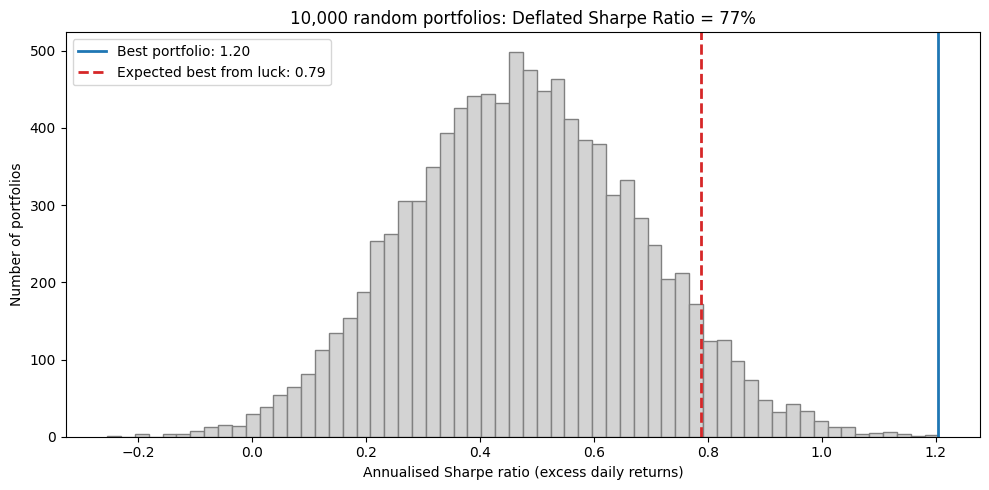

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# ===== STEP 15: Is the best portfolio real, or just luck? (Deflated Sharpe Ratio) =====
if 'sims' not in globals():                                # check the earlier steps are still in memory
    raise RuntimeError('Colab has reset. Run Steps 1-12 again first (Runtime > Run before), then this cell.')
from scipy.stats import norm, skew, kurtosis     # statistics tools (normal distribution, skew, kurtosis)

rf_daily = (1 + RISK_FREE) ** (1 / TRADING_DAYS) - 1     # convert the 4.98% yearly risk-free rate to a daily rate

# 1. Rebuild the daily returns of all 10,000 random portfolios
W = np.vstack(sims['Weights'].values)                    # table of weights: 10,000 rows x 9 stocks
port_daily = returns[stock_cols].values @ W.T            # daily return of every portfolio (days x 10,000)
excess = port_daily - rf_daily                           # return above the risk-free rate

# 2. Sharpe ratio of every portfolio, in daily terms (the formula needs daily numbers)
sr_all = excess.mean(axis=0) / excess.std(axis=0, ddof=1)
best_i = sr_all.argmax()                                 # the portfolio with the highest Sharpe
sr_best = sr_all[best_i]
T = excess.shape[0]                                      # number of trading days
x = excess[:, best_i]                                    # daily excess returns of the best portfolio
g3 = skew(x)                                             # skew: are big moves more often down (<0) or up (>0)?
g4 = kurtosis(x, fisher=False)                           # kurtosis: how fat the tails are (normal = 3)

# 3. The two formulas from Bailey & Lopez de Prado (2014)
def expected_max_sharpe(var_sr, n_trials):
    # The best Sharpe you would expect from n_trials portfolios that have NO real skill
    gamma = 0.5772156649                                 # Euler-Mascheroni constant
    return np.sqrt(var_sr) * ((1 - gamma) * norm.ppf(1 - 1 / n_trials)
                              + gamma * norm.ppf(1 - 1 / (n_trials * np.e)))

def prob_sharpe(sr, sr_benchmark, T, g3, g4):
    # Probability that the true Sharpe is above sr_benchmark, given T days, skew and kurtosis
    return norm.cdf((sr - sr_benchmark) * np.sqrt(T - 1)
                    / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2))

var_sr = sr_all.var(ddof=1)                              # how much Sharpe ratios differ across the 10,000 tries
sr0 = expected_max_sharpe(var_sr, len(sr_all))           # "luck" hurdle for 10,000 tries
dsr = prob_sharpe(sr_best, sr0, T, g3, g4)               # Deflated Sharpe Ratio
psr = prob_sharpe(sr_best, 0, T, g3, g4)                 # probability Sharpe > 0, ignoring how many we tried

ann = np.sqrt(TRADING_DAYS)                              # to turn daily Sharpe into yearly Sharpe
print(f'Best portfolio Sharpe (annualised):           {sr_best * ann:.2f}')
print(f'Sharpe expected from luck alone, 10,000 tries: {sr0 * ann:.2f}')
print(f'Days of data: {T} | skew: {g3:.2f} | kurtosis: {g4:.2f}')
print(f'Probability Sharpe > 0 if we had tried only 1:  {psr:.1%}')
print(f'DEFLATED SHARPE RATIO (allowing for 10,000 tries): {dsr:.1%}')
print('Rule: above 95% = likely real skill; below 95% = could be luck')

# 4. How the answer changes with the number of tries
rows = [{'Portfolios tried': 1, 'Luck hurdle (annual Sharpe)': 0.0, 'Probability result is real': psr}]
for n in [10, 100, 1000, 10000]:
    h = expected_max_sharpe(var_sr, n)
    rows.append({'Portfolios tried': n, 'Luck hurdle (annual Sharpe)': h * ann,
                 'Probability result is real': prob_sharpe(sr_best, h, T, g3, g4)})
dsr_table = pd.DataFrame(rows).set_index('Portfolios tried')
dsr_table.to_csv('deflated_sharpe.csv')
display(dsr_table.style.format({'Luck hurdle (annual Sharpe)': '{:.2f}', 'Probability result is real': '{:.1%}'}))

# 5. Chart: all 10,000 Sharpe ratios, the best one, and the luck hurdle
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(sr_all * ann, bins=60, color='lightgrey', edgecolor='grey')
ax.axvline(sr_best * ann, color='tab:blue', linewidth=2, label=f'Best portfolio: {sr_best * ann:.2f}')
ax.axvline(sr0 * ann, color='tab:red', linestyle='--', linewidth=2, label=f'Expected best from luck: {sr0 * ann:.2f}')
ax.set_xlabel('Annualised Sharpe ratio (excess daily returns)')
ax.set_ylabel('Number of portfolios')
ax.set_title(f'10,000 random portfolios: Deflated Sharpe Ratio = {dsr:.0%}')
ax.legend()
plt.tight_layout(); plt.savefig('deflated_sharpe.png', dpi=150); plt.show()

# 6. Download the new files
from google.colab import files
files.download('deflated_sharpe.csv'); files.download('deflated_sharpe.png')

Finding: The best portfolio’s Sharpe ratio (1.20) beats the 0.79 expected from luck with 10,000 tries, but the Deflated Sharpe Ratio is only 77%, below the 95% standard. With one try it would be 98%. So the “optimised” portfolio may be luck, and I would not rely on it.

In [16]:
!zip -q results.zip *.csv *.png      # put all result files into one zip file
from google.colab import files
files.download('results.zip')        # download that one file

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>